- Uses BiomedCLIP, multimodal medical model
- Vision transformer uses timm library
- Attention dropout: regularization trick for training. Reduce overfitting by zeroing out a portion of values
- Forward hook: attach a function to a module (PyTorch) to observe model inputs and outputs

- extract a **14×14 image attention map** (attention rollout). 224x224 image -> 16x16 patches, 14x14 grid

- Use a fusion head on frozen BiomedCLIP for EHR interpretation
    - ViT -> 197 image tokens, [CLS] plus 14x14 grid (196)
    - PubMedBERT text tower: up to 64 text tokens
    - Both extracted once and cached ("freezing" the model)
- Fusion head: 2 layer transformer on [CLS], image tokens, text tokens
    - Words and visual patches attend to each other
- Open-i chest x-ray dataset


In [2]:
%pip install -q open_clip_torch transformers pillow matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import io, base64, re, os, collections
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
from PIL import Image, ImageOps
from datasets import load_dataset
from open_clip import create_model_from_pretrained, get_tokenizer
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
HUB = "hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224" # BiomedCLIP pretrained model
TXT_LEN = 64  # max text tokens
N_LABELS = 8  # num findings to predict

In [4]:
# Data

ds = load_dataset("ykumards/open-i", split="train")
meta = ds.select_columns(["indication", "Problems"])[:]  # text columsn only
ds_img = ds.select_columns(["img_frontal"])

for i in range(3):
    print(repr(meta["indication"][i]), "->", repr(meta["Problems"][i]))

def parse(s): # split into terms
    return [p.strip().lower() for p in (s or "").split(";") if p.strip()]

def clean(s): # clean "X" redactions
    s = re.sub(r"X{2,}", "", s or "").strip()
    return s or "no indication provided"

problems = [parse(p) for p in meta["Problems"]]
counts = collections.Counter(l for ps in problems for l in ps)
LABELS = [l for l, _ in counts.most_common(N_LABELS)]
print("\nTop labels:", counts.most_common(12))
print("Predicting:", LABELS)

'Positive TB test' -> 'normal'
'Preop bariatric surgery.' -> 'Cardiomegaly;Pulmonary Artery'
'rib pain after a XXXX, XXXX XXXX steps this XXXX. Pain to R back, R elbow and R rib XXXX, no previous heart or lung hx, non-XXXX, no hx ca' -> 'normal'

Top labels: [('normal', 1379), ('lung', 553), ('opacity', 509), ('cardiomegaly', 345), ('calcinosis', 332), ('pulmonary atelectasis', 330), ('calcified granuloma', 276), ('thoracic vertebrae', 257), ('cicatrix', 196), ('spine', 174), ('markings', 167), ('pleural effusion', 160)]
Predicting: ['normal', 'lung', 'opacity', 'cardiomegaly', 'calcinosis', 'pulmonary atelectasis', 'calcified granuloma', 'thoracic vertebrae']


In [7]:
# Cache features extracted from open-i

CACHE = "openi_biomedclip_feats.pt"

def to_pil(v):
    if isinstance(v, Image.Image): return v
    if isinstance(v, dict): v = v.get("bytes", v)
    if isinstance(v, str): v = base64.b64decode(v)
    return Image.open(io.BytesIO(v))

def pad_square(img):
    img = img.convert("RGB")
    return ImageOps.pad(img, (max(img.size),) * 2)

model, preprocess = create_model_from_pretrained(HUB)
tokenizer = get_tokenizer(HUB)

if os.path.exists(CACHE):
    print("Cache already exists. Using existing features.")
    d = torch.load(CACHE)
    IMG, TXT, IDS, rows = d["img"], d["txt"], d["ids"], d["rows"]
else:
    print("Creating cache.")
    model.to(device).eval()
    IMG, TXT, IDS, rows = [], [], [], []
    candidates = [i for i, ps in enumerate(problems) if ps]
    with torch.no_grad(), torch.autocast(device_type=device, dtype=torch.float16, enabled=device == "cuda"):
        for s in range(0, len(candidates), 32):
            xs, keep = [], []
            for i in candidates[s:s + 32]:
                try:
                    xs.append(preprocess(pad_square(to_pil(ds_img[i]["img_frontal"])))); keep.append(i)
                except Exception:
                    pass 
            ids = tokenizer([clean(meta["indication"][i]) for i in keep], context_length=TXT_LEN).to(device)
            IMG.append(model.visual.trunk.forward_features(torch.stack(xs).to(device)).half().cpu())
            TXT.append(model.text.transformer(input_ids=ids, attention_mask=(ids != 0).long())
                       .last_hidden_state.half().cpu())
            IDS.append(ids.cpu()); rows += keep
    IMG, TXT, IDS = torch.cat(IMG), torch.cat(TXT), torch.cat(IDS)
    torch.save(dict(img=IMG, txt=TXT, ids=IDS, rows=rows), CACHE)

del model
print("image tokens", tuple(IMG.shape), "| text tokens", tuple(TXT.shape))  # (N,197,768) and (N,64,768)

PAD = IDS == 0
Y = torch.zeros(len(rows), N_LABELS)
for r, i in enumerate(rows):
    for p in problems[i]:
        if p in LABELS: Y[r, LABELS.index(p)] = 1
print("label prevalence:", dict(zip(LABELS, Y.mean(0).round(decimals=3).tolist())))

Cache already exists. Using existing features.
image tokens (3689, 197, 768) | text tokens (3689, 64, 768)
label prevalence: {'normal': 0.36399999260902405, 'lung': 0.13899999856948853, 'opacity': 0.11100000143051147, 'cardiomegaly': 0.0860000029206276, 'calcinosis': 0.07599999755620956, 'pulmonary atelectasis': 0.07999999821186066, 'calcified granuloma': 0.0689999982714653, 'thoracic vertebrae': 0.06599999964237213}


In [8]:
# Train test split

idx = np.arange(len(rows))
tr, tmp = train_test_split(idx, test_size=0.3, random_state=0)
va, te = train_test_split(tmp, test_size=0.5, random_state=0)

def loader(ix, shuffle=False):
    ix = torch.as_tensor(ix)
    return DataLoader(TensorDataset(IMG[ix], TXT[ix], PAD[ix], Y[ix]), batch_size=64, shuffle=shuffle)

train_dl, val_dl, test_dl = loader(tr, True), loader(va), loader(te)
print(len(tr), "train /", len(va), "val /", len(te), "test")

2582 train / 553 val / 554 test


In [9]:
# Fusion model

NI = IMG.shape[1]                       # 197 image tokens: ViT [CLS] + 196 patches

class FusionLayer(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, heads, dropout=0.1, batch_first=True)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Dropout(0.1), nn.Linear(4 * d, d))

    def forward(self, x, pad):
        h = self.n1(x)
        a, w = self.attn(h, h, h, key_padding_mask=pad, need_weights=True, average_attn_weights=True)
        x = x + a
        return x + self.mlp(self.n2(x)), w                  # w: (B, N, N), averaged over heads

class FusionClassifier(nn.Module):
    def __init__(self, n_labels, d_in=768, d=256, heads=4, layers=2):
        super().__init__()
        self.img_proj, self.txt_proj = nn.Linear(d_in, d), nn.Linear(d_in, d)
        self.mod = nn.Embedding(2, d)                        # modality embedding: 0 = image, 1 = text
        self.cls = nn.Parameter(torch.randn(1, 1, d) * 0.02)
        self.layers = nn.ModuleList(FusionLayer(d, heads) for _ in range(layers))
        self.head = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, n_labels))

    def forward(self, img, txt, txt_pad, drop_img=None, drop_txt=None, return_attn=False):
        B, ni = img.size(0), img.size(1)
        x = torch.cat([self.cls.expand(B, -1, -1),
                       self.img_proj(img.float()) + self.mod.weight[0],
                       self.txt_proj(txt.float()) + self.mod.weight[1]], 1)
        pad = torch.cat([torch.zeros(B, 1 + ni, dtype=torch.bool, device=img.device), txt_pad], 1)
        if drop_img is not None: pad[:, 1:1 + ni] |= drop_img[:, None]     # hide a whole modality per sample
        if drop_txt is not None: pad[:, 1 + ni:] |= drop_txt[:, None]
        attns = []
        for layer in self.layers:
            x, w = layer(x, pad)
            attns.append(w)
        logits = self.head(x[:, 0])
        return (logits, attns) if return_attn else logits

net = FusionClassifier(N_LABELS).to(device)
print(f"{sum(p.numel() for p in net.parameters()):,} trainable parameters")

1,976,584 trainable parameters


In [10]:
# Train

# about 3 min/epoch on CPU

@torch.no_grad()
def evaluate(dl, use_img=True, use_txt=True):
    net.eval(); P, T = [], []
    for img, txt, pad, y in dl:
        B = img.size(0)
        logits = net(img.to(device), txt.to(device), pad.to(device),
                     drop_img=torch.full((B,), not use_img, dtype=torch.bool, device=device),
                     drop_txt=torch.full((B,), not use_txt, dtype=torch.bool, device=device))
        P.append(logits.sigmoid().cpu()); T.append(y)
    P, T = torch.cat(P).numpy(), torch.cat(T).numpy()
    aucs = {LABELS[k]: roc_auc_score(T[:, k], P[:, k]) for k in range(T.shape[1]) if 0 < T[:, k].sum() < len(T)}
    return float(np.mean(list(aucs.values()))), aucs

pos_w = ((1 - Y[tr]).sum(0) / Y[tr].sum(0).clamp(min=1)).clamp(max=20).to(device)   # up-weight rare findings
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_w)
opt = torch.optim.AdamW(net.parameters(), lr=2e-4, weight_decay=0.05)

best, best_state = 0, None
for epoch in range(5):
    net.train(); total = 0
    for img, txt, pad, y in train_dl:
        img, txt, pad, y = img.to(device), txt.to(device), pad.to(device), y.to(device)
        d_img = torch.rand(len(y), device=device) < 0.15
        d_txt = (torch.rand(len(y), device=device) < 0.15) & ~d_img
        loss = loss_fn(net(img, txt, pad, d_img, d_txt), y)
        opt.zero_grad(); loss.backward(); opt.step()
        total += loss.item() * len(y)
    val_auc, _ = evaluate(val_dl)
    if val_auc > best: best, best_state = val_auc, {k: v.clone() for k, v in net.state_dict().items()}
    print(f"epoch {epoch + 1:2d}  loss {total / len(tr):.4f}  val macro-AUC {val_auc:.3f}")

net.load_state_dict(best_state)

epoch  1  loss 1.2571  val macro-AUC 0.675
epoch  2  loss 1.1566  val macro-AUC 0.699
epoch  3  loss 1.0982  val macro-AUC 0.729
epoch  4  loss 1.0479  val macro-AUC 0.741
epoch  5  loss 1.0336  val macro-AUC 0.749


<All keys matched successfully>

In [11]:
# Test single vs multi modality

for name, kw in [("Image + text", {}), ("Image only", {"use_txt": False}), ("Text only", {"use_img": False})]:
    auc, _ = evaluate(test_dl, **kw)
    print(f"{name:13s} macro-AUC {auc:.3f}")

_, per_label = evaluate(test_dl)
print("\nPer-label AUC (fused):", {k: round(v, 3) for k, v in per_label.items()})

Image + text  macro-AUC 0.755
Image only    macro-AUC 0.750
Text only     macro-AUC 0.598

Per-label AUC (fused): {'normal': 0.782, 'lung': 0.745, 'opacity': 0.778, 'cardiomegaly': 0.905, 'calcinosis': 0.659, 'pulmonary atelectasis': 0.763, 'calcified granuloma': 0.679, 'thoracic vertebrae': 0.729}


In [12]:
# Save the trained head

r = int(te[0])  # reference
net.eval()
with torch.no_grad():
    ref = net(IMG[r:r+1].to(device), TXT[r:r+1].to(device), PAD[r:r+1].to(device)).sigmoid()[0].cpu()

torch.save({"state": net.state_dict(), "labels": LABELS,
            "cfg": {"d": 256, "heads": 4, "layers": 2, "txt_len": TXT_LEN},
            "ref": {"row": r, "probs": ref}}, "fusion.pt")
print("saved", os.path.abspath("fusion.pt"), "| ref row", r)
print(dict(zip(LABELS, ref.tolist())))

saved d:\UA\ECE_525\Project\fusion.pt | ref row 965
{'normal': 0.08236593753099442, 'lung': 0.8174250721931458, 'opacity': 0.8377089500427246, 'cardiomegaly': 0.7555872201919556, 'calcinosis': 0.24191419780254364, 'pulmonary atelectasis': 0.8865535855293274, 'calcified granuloma': 0.17513084411621094, 'thoracic vertebrae': 0.32181593775749207}


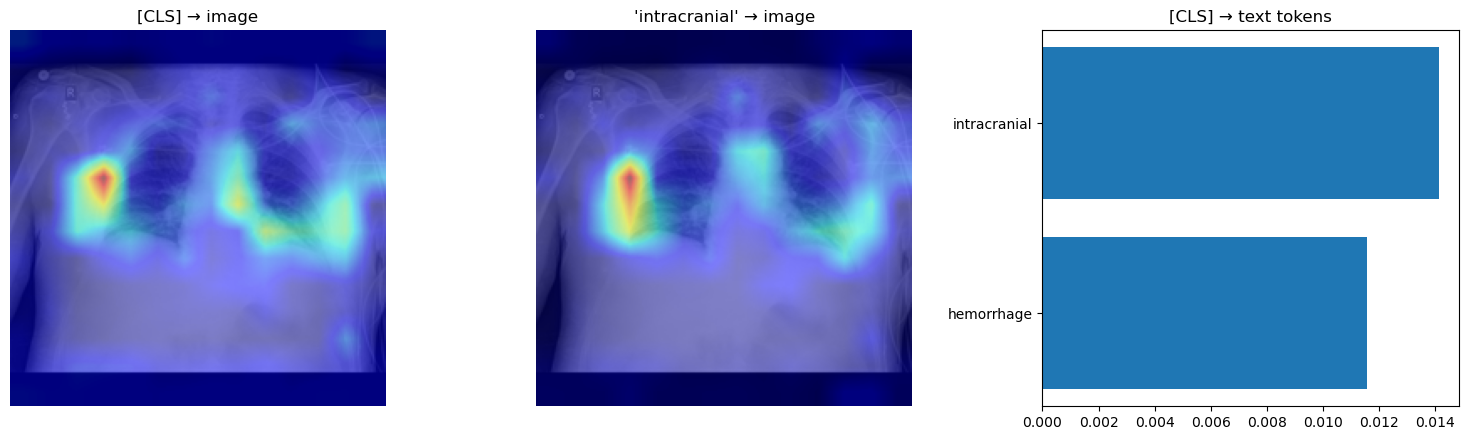

Indication: Intracranial hemorrhage
True: ['lung', 'pulmonary atelectasis']
Pred: {'pulmonary atelectasis': 0.89, 'opacity': 0.84, 'lung': 0.82, 'cardiomegaly': 0.76}


In [13]:
# Attention

SPECIAL = {"[CLS]", "[SEP]", "[PAD]"}

def overlay(ax, base, grid, title):
    h = F.interpolate(grid[None, None].float(), size=224, mode="bilinear", align_corners=False)[0, 0]
    h = (h - h.min()) / (h.max() - h.min() + 1e-8)
    ax.imshow(base); ax.imshow(h, cmap="jet", alpha=0.5); ax.set_title(title); ax.axis("off")

@torch.no_grad()
def explain(r):                                           # r = row index into IMG / TXT / Y
    net.eval()
    logits, attn = net(IMG[r:r + 1].to(device), TXT[r:r + 1].to(device), PAD[r:r + 1].to(device), return_attn=True)
    w = attn[-1][0].cpu()
    probs = logits.sigmoid()[0].cpu()

    toks = tokenizer.tokenizer.convert_ids_to_tokens(IDS[r].tolist())
    t0 = 1 + NI                                           # first text position in the joint sequence
    valid = [j for j, t in enumerate(toks) if t not in SPECIAL]
    scores = {j: w[0, t0 + j].item() for j in valid}
    top = sorted(scores, key=scores.get, reverse=True)[:8]

    raw = pad_square(to_pil(ds_img[rows[r]]["img_frontal"])).resize((224, 224))
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
    overlay(ax[0], raw, w[0, 2:2 + 196].reshape(14, 14), "[CLS] → image")
    overlay(ax[1], raw, w[t0 + top[0], 2:2 + 196].reshape(14, 14), f"'{toks[top[0]]}' → image")
    ax[2].barh([toks[j] for j in top], [scores[j] for j in top]); ax[2].invert_yaxis()
    ax[2].set_title("[CLS] → text tokens")
    plt.tight_layout(); plt.show()

    print("Indication:", clean(meta["indication"][rows[r]]))
    print("True:", [LABELS[k] for k in range(N_LABELS) if Y[r, k] == 1])
    print("Pred:", {LABELS[k]: round(probs[k].item(), 2) for k in probs.argsort(descending=True)[:4].tolist()})

abnormal = [k for k, l in enumerate(LABELS) if l != "normal"]
explain(next(int(i) for i in te if Y[i, abnormal].sum() > 0))

Older code below

In [ ]:
class BiomedCLIPService:
    def __init__(self, device=None):
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.model, self.preprocess = create_model_from_pretrained(HUB)
        self.tokenizer = get_tokenizer(HUB)
        self.model.to(self.device).eval()
        
        # Capture attention weights per layer for vision by disabling timm fused attention and using a forward
        # hook for attention dropout
        self._attn = []
        for blk in self.model.visual.trunk.blocks:
            blk.attn.fused_attn = False
            blk.attn.attn_drop.register_forward_hook(lambda m, inp, out: self._attn.append(inp[0].detach()))

    @torch.no_grad()
    def predict(self, image: Image.Image, prompts: dict):
        """prompts: {label: text prompt}. Returns ({label: prob}, 14x14 attention tensor)."""
        self._attn.clear()
        x = self.preprocess(image.convert("RGB")).unsqueeze(0).to(self.device)
        t = self.tokenizer(list(prompts.values()), context_length=256).to(self.device)

        img = F.normalize(self.model.encode_image(x), dim=-1)
        txt = F.normalize(self.model.encode_text(t), dim=-1)
        probs = (self.model.logit_scale.exp() * img @ txt.T).softmax(-1)[0].cpu()
        return dict(zip(prompts, probs.tolist())), self._rollout()

    def _rollout(self):
        """Attention rollout: multiply head-averaged, residual-corrected attention across layers."""
        r = None
        for a in self._attn:
            a = a.mean(1) # average heads -> (B, N, N)
            a = a + torch.eye(a.size(-1), device=a.device) # account for residual connection
            a = a / a.sum(-1, keepdim=True)
            r = a if r is None else a @ r

        cls_to_patches = r[0, 0, 1:] # [CLS] row, drop the [CLS] column
        n = int(cls_to_patches.numel() ** 0.5)    
        return cls_to_patches.reshape(n, n).cpu()

In [ ]:
svc = BiomedCLIPService()
print("device:", svc.device)

# (1, 12 heads, 197, 197) attention
_ = svc.predict(Image.new("RGB", (224, 224)), {"x": "chest X-ray"})
print(len(svc._attn), "layers captured, shape", tuple(svc._attn[0].shape))

device: cpu
12 layers captured, shape (1, 12, 197, 197)


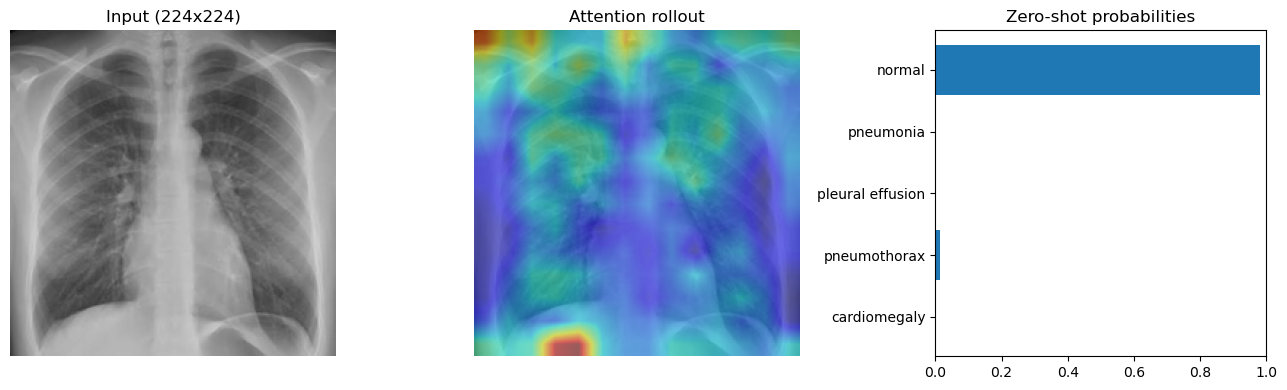

{'normal': 0.981, 'pneumonia': 0.003, 'pleural effusion': 0.0, 'pneumothorax': 0.015, 'cardiomegaly': 0.001}


In [7]:
PROMPTS = {
    "normal":           "normal chest X-ray with no acute findings",
    "pneumonia":        "chest X-ray showing pneumonia",
    "pleural effusion": "chest X-ray showing pleural effusion",
    "pneumothorax":     "chest X-ray showing pneumothorax",
    "cardiomegaly":     "chest X-ray showing cardiomegaly",
}

def show(image, probs, heat, alpha=0.5):
    # Mirror the model's preprocessing (resize + center crop to 224) so the overlay aligns.
    base = ImageOps.fit(image.convert("RGB"), (224, 224), Image.BICUBIC)
    h = F.interpolate(heat[None, None], size=224, mode="bilinear", align_corners=False)[0, 0]
    h = (h - h.min()) / (h.max() - h.min() + 1e-8)

    fig, ax = plt.subplots(1, 3, figsize=(13, 4))
    ax[0].imshow(base, cmap="gray"); ax[0].set_title("Input (224x224)")
    ax[1].imshow(base); ax[1].imshow(h, cmap="jet", alpha=alpha); ax[1].set_title("Attention rollout")
    ax[2].barh(list(probs), list(probs.values())); ax[2].set_xlim(0, 1); ax[2].invert_yaxis()
    ax[2].set_title("Zero-shot probabilities")
    for a in ax[:2]: a.axis("off")
    plt.tight_layout(); plt.show()

image = Image.open(IMAGE_PATH)
probs, heat = svc.predict(image, PROMPTS)
show(image, probs, heat)
print({k: round(v, 3) for k, v in probs.items()})